<a href="https://colab.research.google.com/github/Sasha3424/23145/blob/main/26_27_grsu_ml_ind_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Индивидуальная практическая работа 6. Обучение сети детекции

1. Сделайте копию тетрадки.
2. Заполните тетрадку.

In [3]:
import numpy as np
import cv2
import glob
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import tqdm
import seaborn as sns
import torchvision
import torch
import PIL
from PIL import Image
import json

def show_image(image, figsize=(16, 9), reverse=True):
    plt.figure(figsize=figsize)
    if reverse:
        plt.imshow(image[...,::-1])
    else:
        plt.imshow(image)
    plt.axis('off')
    plt.show()

def save_to_json(filename, data):
    with open(filename, 'w') as f:
        return json.dump(data, f)

def load_from_json(filename):
    with open(filename, 'r') as f:
        return json.load(f)

# Скачиваем датасет

In [ ]:
import gdown

# https://drive.google.com/file/d/1nCaTl4-xx2GZ-YEoo5ma3ogCndrovJUZ/view?usp=sharing

gdrive_file_id = '1nCaTl4-xx2GZ-YEoo5ma3ogCndrovJUZ'

gdown.download(id=gdrive_file_id, output='seminar_obj_data.zip')

In [5]:
!unzip seminar_obj_data.zip >> /dev/null

# Load COCO info

Useful links:
http://cocodataset.org/#home

In [6]:
coco_id_to_name = load_from_json("coco_id_to_name.json")

In [7]:
coco_id_to_name = {int(key): value for key, value in coco_id_to_name.items()}

In [8]:
len(coco_id_to_name)

80

In [9]:
list(coco_id_to_name.values())

['person',
 'bicycle',
 'car',
 'motorcycle',
 'airplane',
 'bus',
 'train',
 'truck',
 'boat',
 'traffic light',
 'fire hydrant',
 'stop sign',
 'parking meter',
 'bench',
 'bird',
 'cat',
 'dog',
 'horse',
 'sheep',
 'cow',
 'elephant',
 'bear',
 'zebra',
 'giraffe',
 'backpack',
 'umbrella',
 'handbag',
 'tie',
 'suitcase',
 'frisbee',
 'skis',
 'snowboard',
 'sports ball',
 'kite',
 'baseball bat',
 'baseball glove',
 'skateboard',
 'surfboard',
 'tennis racket',
 'bottle',
 'wine glass',
 'cup',
 'fork',
 'knife',
 'spoon',
 'bowl',
 'banana',
 'apple',
 'sandwich',
 'orange',
 'broccoli',
 'carrot',
 'hot dog',
 'pizza',
 'donut',
 'cake',
 'chair',
 'couch',
 'potted plant',
 'bed',
 'dining table',
 'toilet',
 'tv',
 'laptop',
 'mouse',
 'remote',
 'keyboard',
 'cell phone',
 'microwave',
 'oven',
 'toaster',
 'sink',
 'refrigerator',
 'book',
 'clock',
 'vase',
 'scissors',
 'teddy bear',
 'hair drier',
 'toothbrush']

In [51]:
import torchvision
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

model = torchvision.models.detection.fasterrcnn_resnet50_fpn(pretrained=True, progress=True,
                            num_classes=91, pretrained_backbone=True)

In [52]:
from torchvision import transforms

to_tensor = transforms.ToTensor()

def val_transform(img):
    img_tensor = to_tensor(img)
    return img_tensor.unsqueeze(0)

def visualize_prediction(file, model, device='cuda', verbose=True, thresh=0.0, n_colors=None):
    img = Image.open(file)
    img_tensor = val_transform(img)
    model.to(device)
    model.eval()
    with torch.no_grad():
        predictions = model(img_tensor.to(device)) # list of size 1
    prediction = predictions[0]

    if n_colors is None:
        n_colors = model.roi_heads.box_predictor.cls_score.out_features

    palette = sns.color_palette(None, n_colors)

    # visualize
    img = cv2.imread(file, cv2.COLOR_BGR2RGB)
    for i in range(len(prediction['boxes'])):
        x1, x2, x3, x4 = map(int, prediction['boxes'][i].tolist())
        label = int(prediction['labels'][i].cpu())
        score = float(prediction['scores'][i].cpu())
        name = coco_id_to_name[label]
        color = palette[label]
        if verbose:
            if score > thresh:
                print ('Class: {}, Confidence: {}'.format(name, score))
        if score > thresh:
            image = cv2.rectangle(img, (x1, x2), (x3, x4), np.array(color) * 255, 2)
            cv2.putText(image, name, (x1, x2-10), cv2.FONT_HERSHEY_SIMPLEX, 0.7, np.array(color) * 255, 2)
    show_image(image)
    return prediction

### Датасет Open images:
https://storage.googleapis.com/openimages/web/index.html

In [47]:
filename_to_bbox_train_dict = load_from_json('filename_to_bbox_train.json')

In [48]:
filename_to_bbox_val_dict = load_from_json('filename_to_bbox_val.json')

In [49]:
len(filename_to_bbox_train_dict), len(filename_to_bbox_val_dict)

(1313, 200)

# Визуализируем датасет

In [15]:
def visualize_from_dataset(file, filename_to_bbox_dict):
    img = cv2.imread(file, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    for i in range(len(filename_to_bbox_dict[file])):
        x_min, x_max, y_min, y_max = filename_to_bbox_dict[file][i]
        x_min, y_min, x_max, y_max = int(x_min * w), int(y_min * h), int(x_max * w), int(y_max * h)
        image = cv2.rectangle(img, (x_min, y_min), (x_max, y_max), (0, 255, 0), 2)
    show_image(image)

In [16]:
train_filenames = list(filename_to_bbox_train_dict.keys()),
len(train_filenames[0])

1313

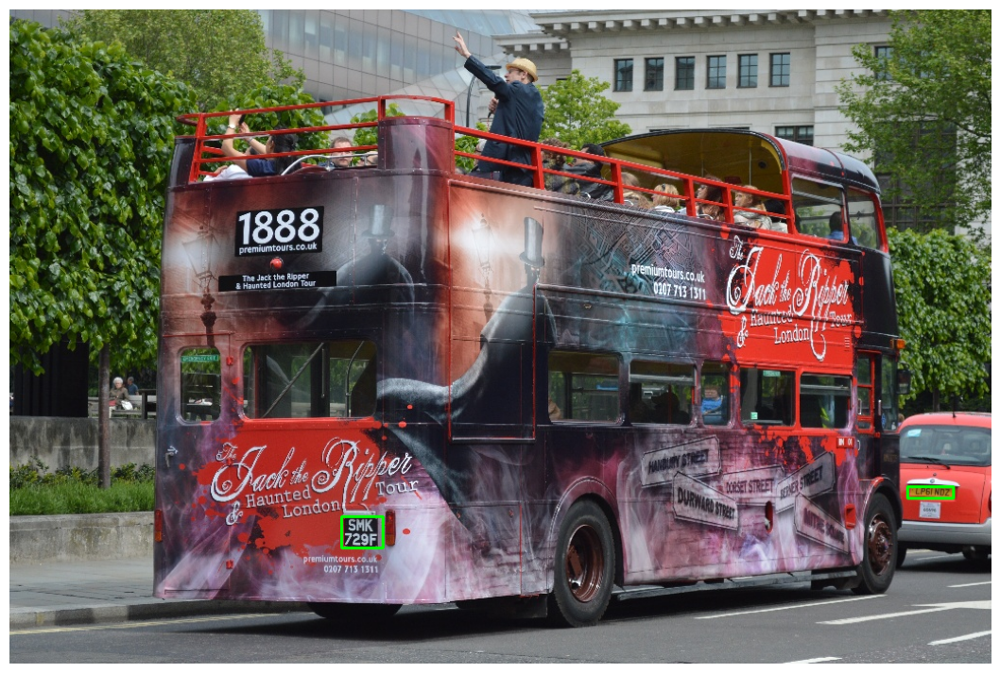

In [17]:
filename = np.random.choice(train_filenames[0])
visualize_from_dataset(filename, filename_to_bbox_train_dict)

In [18]:
val_filenames = list(filename_to_bbox_val_dict.keys())

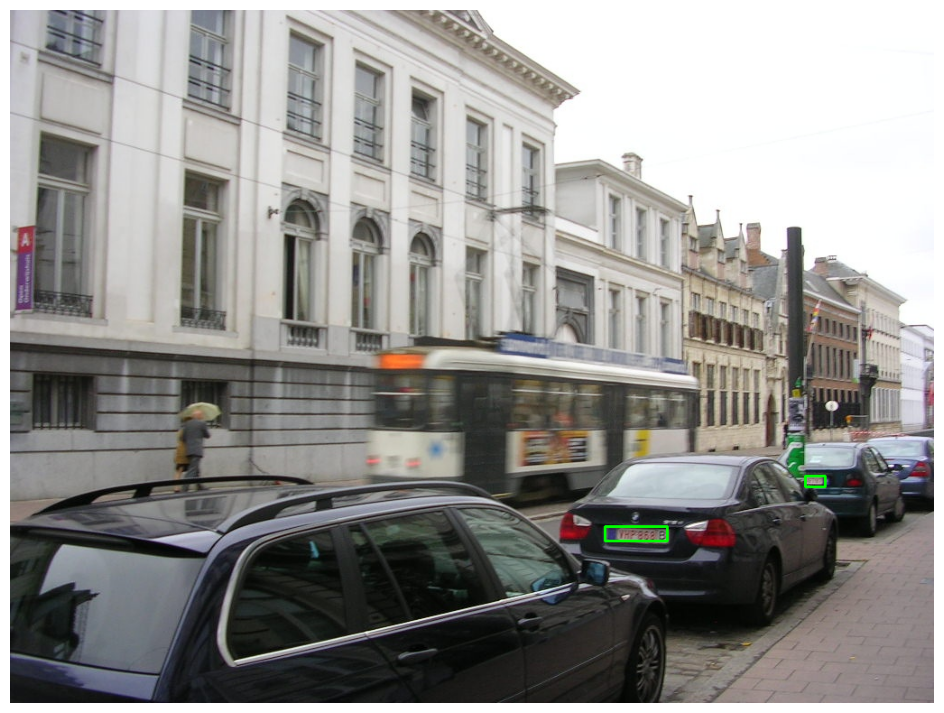

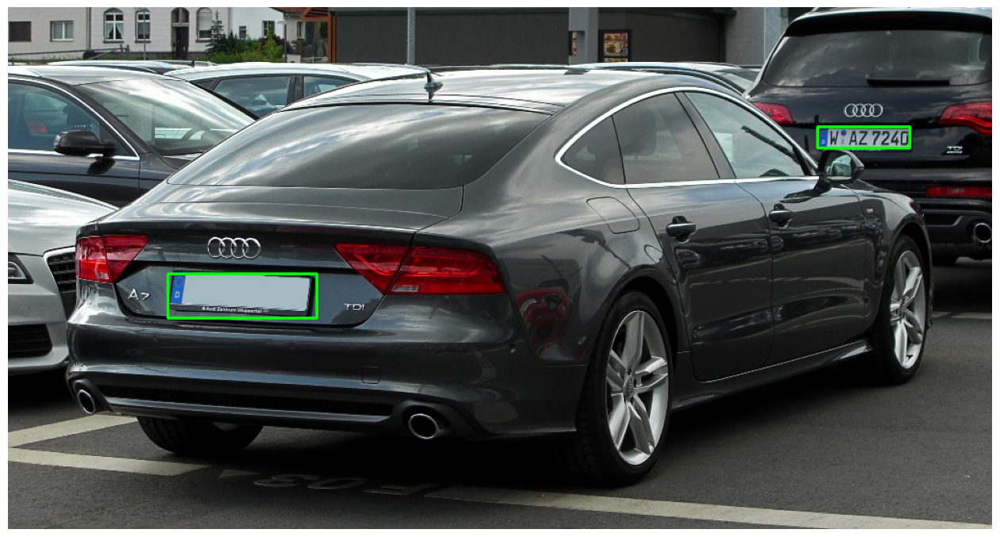

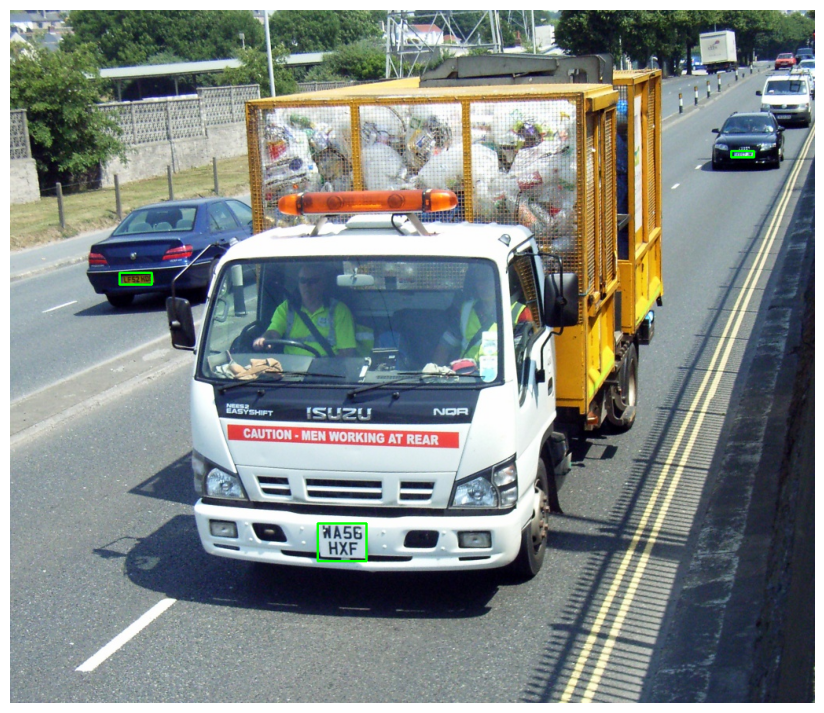

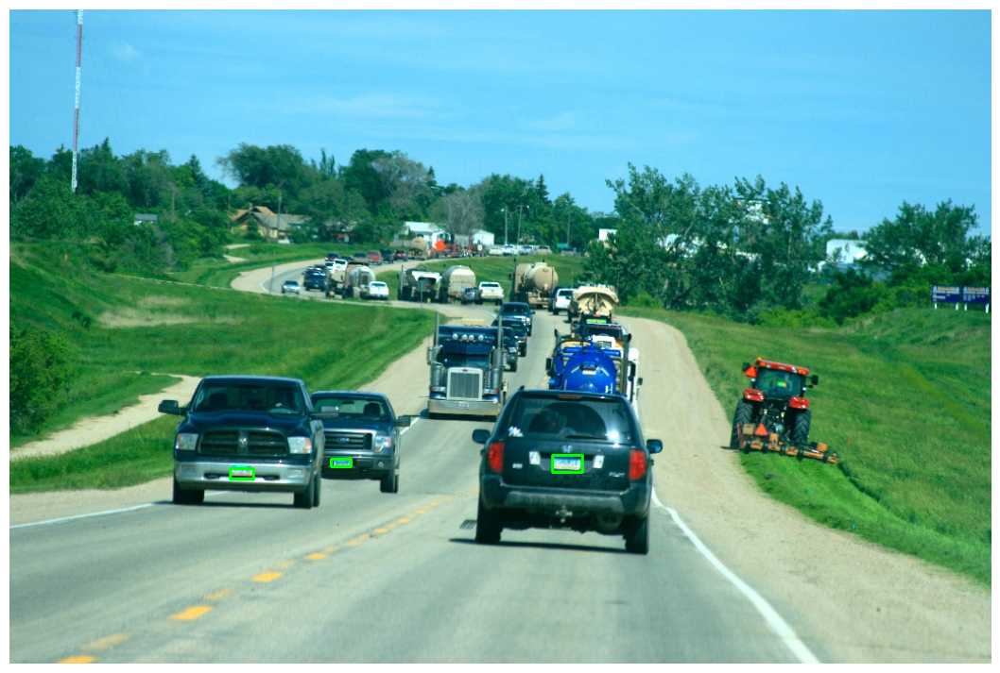

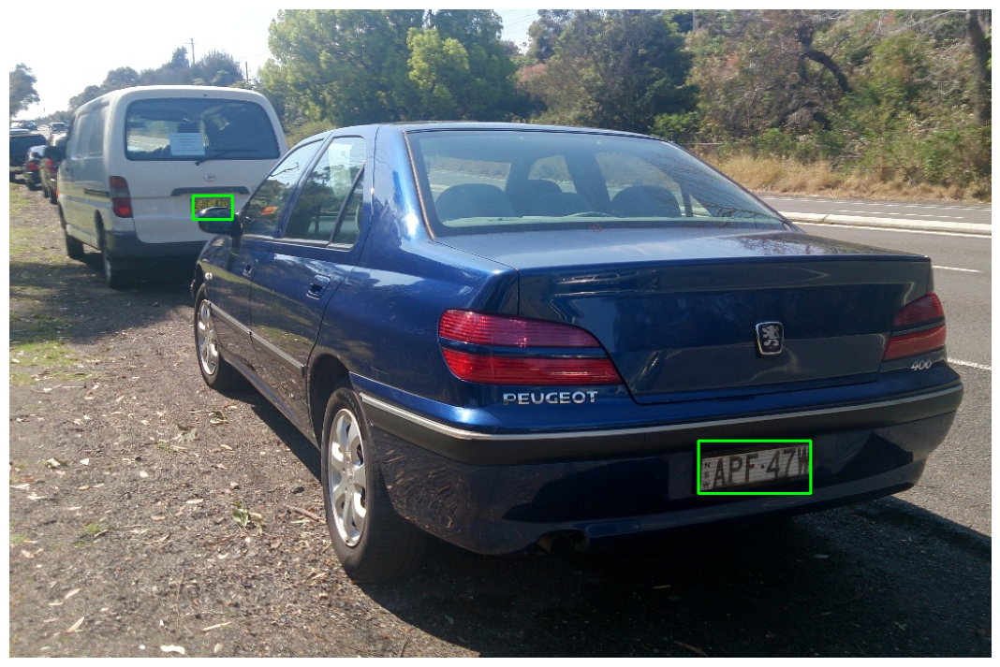

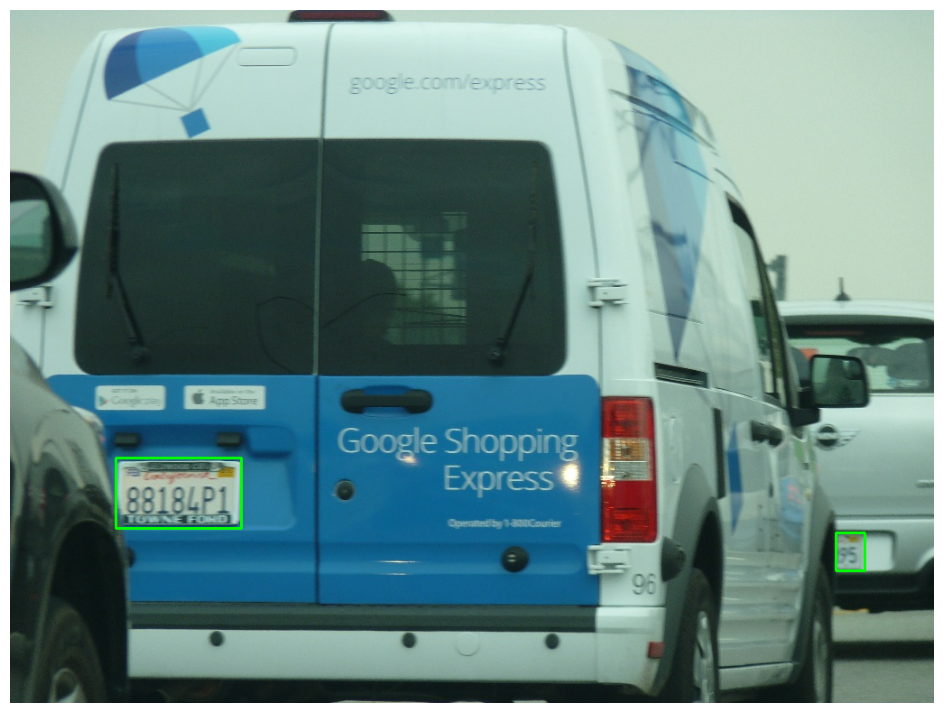

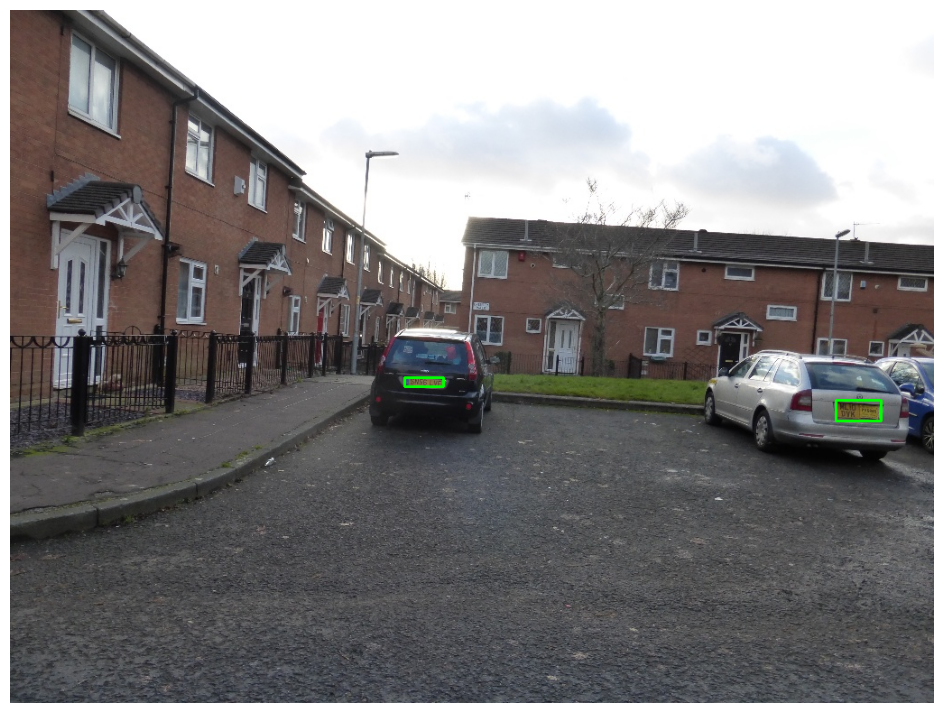

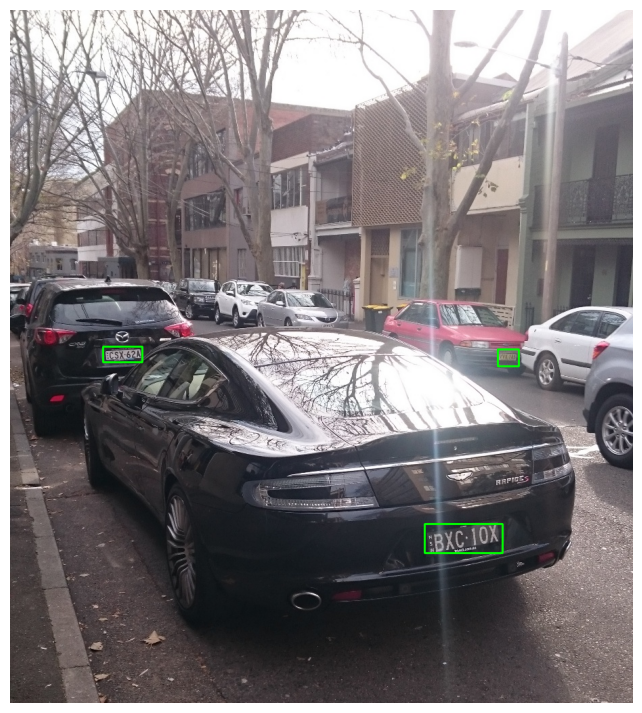

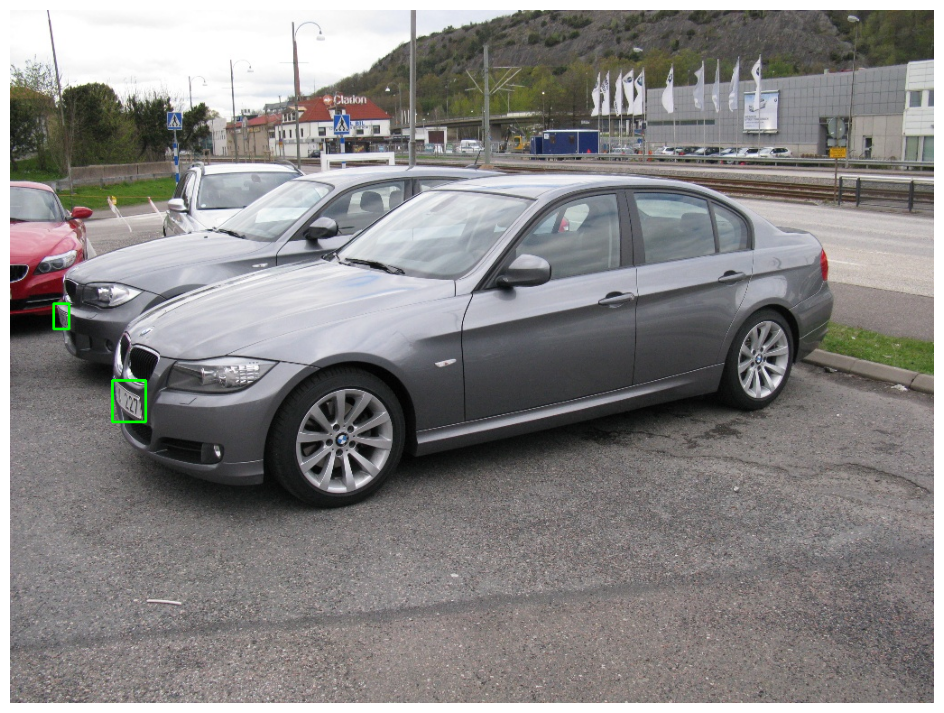

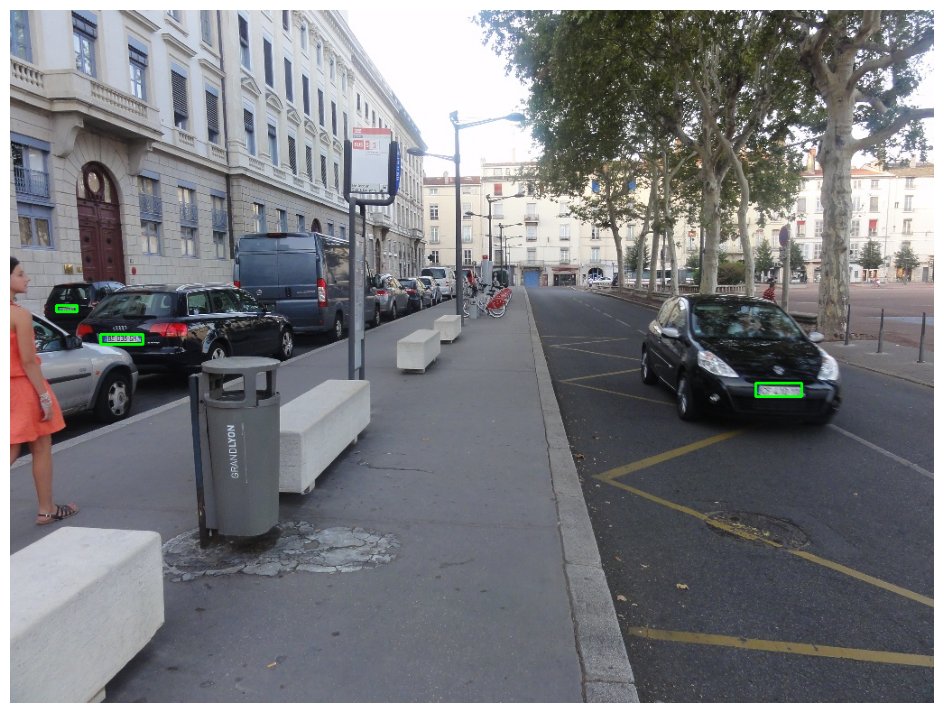

In [19]:
for filename in np.random.choice(val_filenames, 10):
    visualize_from_dataset(filename, filename_to_bbox_val_dict)

# Создадим класс датасета

In [20]:
import os
import numpy as np
import torch
import torch.utils.data
from PIL import Image
import json
from torchvision import transforms

class DetectionDataset(torch.utils.data.Dataset):
    def __init__(self, data_dict_file, transforms=None):
        self.transforms = transforms

        with open(data_dict_file, 'r') as f:
            self.data_dict = json.load(f)

        self.imgs = list(self.data_dict.keys())

    def __getitem__(self, idx):
        # load images ad masks
        img_path = self.imgs[idx]
        img = Image.open(img_path).convert("RGB")
        w, h = img.size

        num_objs = len(self.data_dict[img_path])
        boxes = []
        for i in range(num_objs):
            bbox = self.data_dict[img_path][i]
            xmin = bbox[0] * w
            xmax = bbox[1] * w
            ymin = bbox[2] * h
            ymax = bbox[3] * h
            boxes.append([xmin, ymin, xmax, ymax])

        boxes = torch.as_tensor(boxes, dtype=torch.float32)
        # there is only one class
        labels = torch.ones((num_objs,), dtype=torch.int64)

        # is crowd
        iscrowd = torch.zeros((num_objs,), dtype=torch.int64)

        image_id = torch.tensor([idx])
        area = (boxes[:, 3] - boxes[:, 1]) * (boxes[:, 2] - boxes[:, 0])

        target = {}
        target["boxes"] = boxes
        target["labels"] = labels
        target["image_id"] = image_id
        target["area"] = area
        target["iscrowd"] = iscrowd

        if self.transforms is not None:
            img = self.transforms(img)

        return img, target

    def __len__(self):
        return len(self.imgs)

# Create transforms

In [21]:
img_transforms = transforms.Compose([
    transforms.ToTensor()
])

# Load datasets

In [22]:
# collate_fn needs for batch
def collate_fn(batch):
    return tuple(zip(*batch))

In [23]:

# use our dataset and defined transformations
train_dataset = DetectionDataset('filename_to_bbox_train.json', img_transforms)
val_dataset = DetectionDataset('filename_to_bbox_val.json', img_transforms)

# Make dataloaders

In [55]:
# define training and validation data loaders
data_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=2, shuffle=True, num_workers=2, # Уменьшили батч и потоки
    collate_fn=collate_fn, drop_last=True)

data_loader_val = torch.utils.data.DataLoader(
    val_dataset, batch_size=1, shuffle=False, num_workers=2,
    collate_fn=collate_fn, drop_last=False)

# Load model

In [25]:
model.roi_heads.box_predictor

FastRCNNPredictor(
  (cls_score): Linear(in_features=1024, out_features=91, bias=True)
  (bbox_pred): Linear(in_features=1024, out_features=364, bias=True)
)

In [27]:
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

model = torchvision.models.detection.fasterrcnn_resnet50_fpn(
    pretrained=True, pretrained_backbone=True
)

# Меняем голову под нашу задачу: 2 класса (0 — фон, 1 — plate)
num_classes = 2
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

In [28]:
assert model.roi_heads.box_predictor.cls_score.in_features == 1024
assert model.roi_heads.box_predictor.cls_score.out_features == 2
assert model.roi_heads.box_predictor.bbox_pred.out_features == 8

# Включить обучение только region-proposal сети и головы

In [53]:
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model.to(device)

# 1) Замораживаем backbone
for param in model.backbone.parameters():
    param.requires_grad = False

# 2) Замораживаем всё в roi_heads, кроме box_predictor
for name, param in model.roi_heads.named_parameters():
    if not name.startswith('box_predictor'):
        param.requires_grad = False

# 3) RPN остаётся обучаемым по умолчанию — ничего не делаем

# Собираем обучаемые параметры
params = [p for p in model.parameters() if p.requires_grad]

print("Количество обучаемых тензоров:", len(params))
for n, p in model.named_parameters():
    if p.requires_grad:
        print("  trainable:", n, tuple(p.shape))

# Проверка: обучаются только RPN и box_predictor
for n, p in model.named_parameters():
    if p.requires_grad:
        assert n.startswith('rpn') or n.startswith('roi_heads.box_predictor'), \
            f"Лишний обучаемый параметр: {n}"
print("OK: обучаются только RPN и box_predictor")

Количество обучаемых тензоров: 10
  trainable: rpn.head.conv.0.0.weight (256, 256, 3, 3)
  trainable: rpn.head.conv.0.0.bias (256,)
  trainable: rpn.head.cls_logits.weight (3, 256, 1, 1)
  trainable: rpn.head.cls_logits.bias (3,)
  trainable: rpn.head.bbox_pred.weight (12, 256, 1, 1)
  trainable: rpn.head.bbox_pred.bias (12,)
  trainable: roi_heads.box_predictor.cls_score.weight (91, 1024)
  trainable: roi_heads.box_predictor.cls_score.bias (91,)
  trainable: roi_heads.box_predictor.bbox_pred.weight (364, 1024)
  trainable: roi_heads.box_predictor.bbox_pred.bias (364,)
OK: обучаются только RPN и box_predictor


In [54]:
# and a learning rate scheduler which decreases the learning rate by
# 10x every 3 epochs
optimizer = torch.optim.SGD(params, lr=0.005,
                            momentum=0.9, weight_decay=0.0005)

lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer,
                                               step_size=30,
                                               gamma=0.1)

# Обучение

In [36]:
!pip3 install pycocotools

Во время обучение выход модели выглядит так:
```
loss_dict = model( images, targets)
print (loss_dict)
{'loss_classifier': tensor(1.5606, device='cuda:0', grad_fn=<NILLossBackward>),
'loss_box_reg': tensor (0.0043, device='cuda:0', grad_fn=<DivBackward0>),
'loss_objectness': tensor(2.0158, device='cuda:0'),
'loss_rpn_box_reg': tensor(1.4645, device='cuda:0')}
```

In [37]:
from engine import evaluate

In [38]:
import math
import sys
import time
import torch
import utils
import tqdm
import numpy as np

In [39]:
def train_one_epoch(model, optimizer, data_loader, device, epoch):
    model.train()
    losses_hist = []
    for images, targets in tqdm.tqdm(data_loader):
        images = list(image.to(device) for image in images)
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        # Словарь лоссов: loss_classifier, loss_box_reg, loss_objectness, loss_rpn_box_reg
        loss_dict = model(images, targets)

        # Суммируем все лоссы
        losses = sum(loss for loss in loss_dict.values())
        loss_value = losses.item()
        losses_hist.append(loss_value)

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

    print(f"Loss {np.mean(losses_hist)}")

# Запустим обучение

In [70]:
num_epochs=10
for epoch in range(num_epochs):
    train_one_epoch(model, optimizer, data_loader, device, epoch)
    # update the learning rate
    lr_scheduler.step()
    # evaluate on the test dataset
    # evaluate(model, data_loader_val, device=device)
    # torch.save(model.state_dict(), 'model_state_dict_last.pth')

100%|██████████| 656/656 [03:16<00:00,  3.34it/s]


Loss 0.2758191793521003


100%|██████████| 656/656 [03:15<00:00,  3.36it/s]


Loss 0.2745548989283057


100%|██████████| 656/656 [03:14<00:00,  3.37it/s]


Loss 0.27531202196529725


... (10 outputs left out)

100%|██████████| 656/656 [03:15<00:00,  3.35it/s]


Loss 0.26488476106896996


100%|██████████| 656/656 [03:15<00:00,  3.35it/s]

Loss 0.26541561637891503


## Сохраним модель

In [71]:
torch.save(model.state_dict(), 'model_state_dict_workshop_final.pth')

In [72]:
model.to(device)

FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=0.0)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=0.0)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=0.0)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=0.0)
          (relu): ReLU(

In [73]:
evaluate(model, data_loader_val, device=device)

creating index...
index created!
Test:  [  0/200]  eta: 0:00:59  model_time: 0.1730 (0.1730)  evaluator_time: 0.0022 (0.0022)  time: 0.2990  data: 0.1206  max mem: 3862
Test:  [100/200]  eta: 0:00:12  model_time: 0.1135 (0.1156)  evaluator_time: 0.0021 (0.0027)  time: 0.1274  data: 0.0060  max mem: 3862
Test:  [199/200]  eta: 0:00:00  model_time: 0.1160 (0.1161)  evaluator_time: 0.0020 (0.0028)  time: 0.1270  data: 0.0056  max mem: 3862
Test: Total time: 0:00:25 (0.1297 s / it)
Averaged stats: model_time: 0.1160 (0.1161)  evaluator_time: 0.0020 (0.0028)
Accumulating evaluation results...
DONE (t=0.06s).
IoU metric: bbox
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.289
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.631
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.187
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.211
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=med

# Визуализируем предсказания для валидации

In [75]:
def visualize_prediction_plate(file, model, device='cuda', verbose=True, thresh=0.0,
                               n_colors=None, id_to_name=None):
    img = Image.open(file)
    img_tensor = val_transform(img)
    model.to(device)
    model.eval()
    with torch.no_grad():
        predictions = model(img_tensor.to(device)) # list of size 1
    prediction = predictions[0]

    if n_colors is None:
        n_colors = model.roi_heads.box_predictor.cls_score.out_features

    palette = sns.color_palette(None, n_colors)

    # visualize
    img = cv2.imread(file, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    image = img
    for i in range(len(prediction['boxes'])):
        x_min, y_min, x_max, y_max = map(int, prediction['boxes'][i].tolist())
        label = int(prediction['labels'][i].cpu())
        score = float(prediction['scores'][i].cpu())
        name = id_to_name[label]
        color = palette[label]
        if verbose:
            if score > thresh:
                print ('Class: {}, Confidence: {}'.format(name, score))
        if score > thresh:
            image = cv2.rectangle(img, (x_min, y_min), (x_max, y_max), np.array(color) * 255, 2)
            cv2.putText(image, name, (x_min, y_min-10), cv2.FONT_HERSHEY_SIMPLEX, 0.7, np.array(color) * 255, 2)
    show_image(image)
    return prediction

# Визуализируем предсказания

In [78]:
val_filenames = list(filename_to_bbox_val_dict.keys())

Class: plate, Confidence: 0.9355801343917847
Class: plate, Confidence: 0.8109334707260132


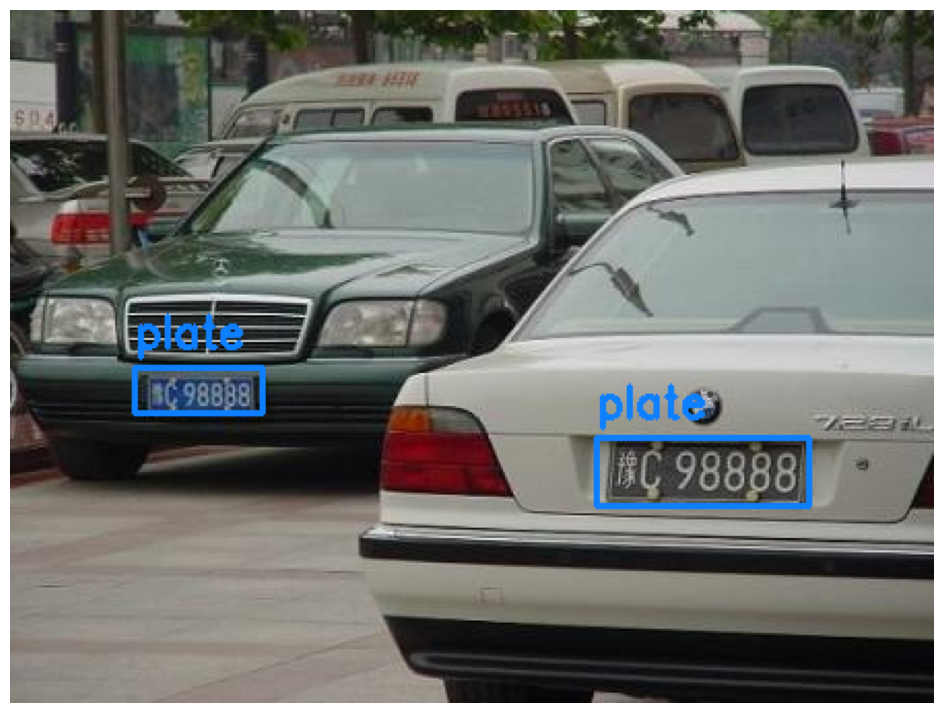

{'boxes': tensor([[6.0613e+01, 1.7354e+02, 1.2202e+02, 1.9563e+02],
         [2.8430e+02, 2.0722e+02, 3.8715e+02, 2.4011e+02],
         [3.5265e+01, 1.0528e+02, 4.7382e+01, 1.1289e+02],
         [4.3294e+02, 5.6616e+01, 4.4800e+02, 6.9178e+01],
         [7.7438e+01, 1.7616e+02, 1.1017e+02, 1.9589e+02],
         [2.9122e+02, 2.0694e+02, 3.3103e+02, 2.4253e+02],
         [6.2756e+01, 1.4145e+02, 1.4687e+02, 1.6693e+02],
         [4.6474e+01, 1.7063e+02, 1.5275e+02, 2.1000e+02],
         [1.4625e+00, 1.9160e+02, 1.6611e+01, 2.1434e+02],
         [2.2409e+01, 9.7261e+01, 4.7262e+01, 1.1198e+02],
         [6.6850e+01, 1.0064e+02, 8.1948e+01, 1.1041e+02],
         [6.4983e+01, 1.7986e+02, 1.2912e+02, 2.1562e+02],
         [6.2873e+01, 1.8283e+02, 1.1987e+02, 1.9874e+02],
         [3.5837e+02, 1.4688e+02, 3.9263e+02, 1.5726e+02],
         [7.2052e+01, 1.7466e+02, 9.6728e+01, 1.9483e+02],
         [2.7379e+02, 2.0320e+02, 4.0065e+02, 2.6928e+02],
         [7.4157e+01, 9.0330e+01, 9.0807e+01, 9

In [80]:
filename = np.random.choice(val_filenames)
visualize_prediction_plate(filename, model, id_to_name={1: 'plate'}, thresh=0.7)